In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

In [2]:
df=pd.read_csv(r"Electric_Grid_Stability_.csv")
df

,tau1,tau2,tau3,tau4,p1,p2,p3,p4,g1,g2,g3,g4,stab,stabf
0,2.959060,3.079885,8.381025,9.780754,3.763085,-0.782604,-1.257395,-1.723086,0.650456,0.859578,0.887445,0.958034,0.055347,unstable
1,9.304097,4.902524,3.047541,1.369357,5.067812,-1.940058,-1.872742,-1.255012,0.413441,0.862414,0.562139,0.781760,-0.005957,stable
2,8.971707,8.848428,3.046479,1.214518,3.405158,-1.207456,-1.277210,-0.920492,0.163041,0.766689,0.839444,0.109853,0.003471,unstable
3,0.716415,7.669600,4.486641,2.340563,3.963791,-1.027473,-1.938944,-0.997374,0.446209,0.976744,0.929381,0.362718,0.028871,unstable
4,3.134112,7.608772,4.943759,9.857573,3.525811,-1.125531,-1.845975,-0.554305,0.797110,0.455450,0.656947,0.820923,0.049860,unstable
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,2.930406,9.487627,2.376523,6.187797,3.343416,-0.658054,-1.449106,-1.236256,0.601709,0.779642,0.813512,0.608385,0.023892,unstable
9996,3.392299,1.274827,2.954947,6.894759,4.349512,-1.663661,-0.952437,-1.733414,0.502079,0.567242,0.285880,0.366120,-0.025803,stable
9997,2.364034,2.842030,8.776391,1.008906,4.299976,-1.380719,-0.943884,-1.975373,0.487838,0.986505,0.149286,0.145984,-0.031810,stable
9998,9.631511,3.994398,2.757071,7.821347,2.514755,-0.966330,-0.649915,-0.898510,0.365246,0.587558,0.889118,0.818391,0.037789,unstable


In [3]:
df.shape

(10000, 14)

In [4]:
df.head()

,tau1,tau2,tau3,tau4,p1,p2,p3,p4,g1,g2,g3,g4,stab,stabf
0,2.959060,3.079885,8.381025,9.780754,3.763085,-0.782604,-1.257395,-1.723086,0.650456,0.859578,0.887445,0.958034,0.055347,unstable
1,9.304097,4.902524,3.047541,1.369357,5.067812,-1.940058,-1.872742,-1.255012,0.413441,0.862414,0.562139,0.781760,-0.005957,stable
2,8.971707,8.848428,3.046479,1.214518,3.405158,-1.207456,-1.277210,-0.920492,0.163041,0.766689,0.839444,0.109853,0.003471,unstable
3,0.716415,7.669600,4.486641,2.340563,3.963791,-1.027473,-1.938944,-0.997374,0.446209,0.976744,0.929381,0.362718,0.028871,unstable
4,3.134112,7.608772,4.943759,9.857573,3.525811,-1.125531,-1.845975,-0.554305,0.797110,0.455450,0.656947,0.820923,0.049860,unstable


In [5]:
df.tail()

,tau1,tau2,tau3,tau4,p1,p2,p3,p4,g1,g2,g3,g4,stab,stabf
9995,2.930406,9.487627,2.376523,6.187797,3.343416,-0.658054,-1.449106,-1.236256,0.601709,0.779642,0.813512,0.608385,0.023892,unstable
9996,3.392299,1.274827,2.954947,6.894759,4.349512,-1.663661,-0.952437,-1.733414,0.502079,0.567242,0.285880,0.366120,-0.025803,stable
9997,2.364034,2.842030,8.776391,1.008906,4.299976,-1.380719,-0.943884,-1.975373,0.487838,0.986505,0.149286,0.145984,-0.031810,stable
9998,9.631511,3.994398,2.757071,7.821347,2.514755,-0.966330,-0.649915,-0.898510,0.365246,0.587558,0.889118,0.818391,0.037789,unstable
9999,6.530527,6.781790,4.349695,8.673138,3.492807,-1.390285,-1.532193,-0.570329,0.073056,0.505441,0.378761,0.942631,0.045263,unstable


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   tau1    9990 non-null   float64
 1   tau2    9985 non-null   float64
 2   tau3    9990 non-null   float64
 3   tau4    9985 non-null   float64
 4   p1      9983 non-null   float64
 5   p2      9987 non-null   float64
 6   p3      9990 non-null   float64
 7   p4      9982 non-null   float64
 8   g1      9985 non-null   float64
 9   g2      9988 non-null   float64
 10  g3      9990 non-null   float64
 11  g4      9991 non-null   float64
 12  stab    10000 non-null  float64
 13  stabf   10000 non-null  str    
dtypes: float64(13), str(1)
memory usage: 1.1 MB


In [7]:
df.describe()

,tau1,tau2,tau3,tau4,p1,p2,p3,p4,g1,g2,g3,g4,stab
count,9990.000000,9985.000000,9990.000000,9985.000000,9983.000000,9987.000000,9990.000000,9982.000000,9985.000000,9988.000000,9990.000000,9991.000000,10000.000000
mean,5.249897,5.250174,5.249478,5.250383,3.750354,-1.249910,-1.249895,-1.250553,0.525085,0.525094,0.524977,0.524916,0.015731
std,2.742521,2.743242,2.742197,2.743198,0.751704,0.433048,0.433124,0.432960,0.274273,0.274209,0.274194,0.274305,0.036919
min,0.500793,0.500141,0.500788,0.500473,1.582590,-1.999891,-1.999945,-1.999926,0.050009,0.050053,0.050054,0.050028,-0.080760
25%,2.874433,2.874959,2.875974,2.875028,3.218986,-1.624940,-1.625095,-1.625382,0.287654,0.287716,0.287568,0.287314,-0.015557
50%,5.251216,5.248703,5.249979,5.250280,3.751413,-1.249619,-1.249751,-1.251070,0.525119,0.525130,0.525015,0.524937,0.017142
75%,7.624352,7.625089,7.623076,7.624739,4.282469,-0.874953,-0.874811,-0.875545,0.762618,0.762529,0.762314,0.762456,0.044878
max,9.999469,9.999837,9.999450,9.999443,5.864418,-0.500108,-0.500072,-0.500025,0.999937,0.999944,0.999982,0.999930,0.109403


In [8]:
df.columns

Index(['tau1', 'tau2', 'tau3', 'tau4', 'p1', 'p2', 'p3', 'p4', 'g1', 'g2',
       'g3', 'g4', 'stab', 'stabf'],
      dtype='str')

In [9]:
df.drop(columns=['stab'],inplace=True)

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df['stabf'].unique()

<ArrowStringArray>
['unstable', 'stable']
Length: 2, dtype: str

In [12]:
df['stabf'].value_counts()

stabf
unstable    6380
stable      3620
Name: count, dtype: int64

In [13]:
df.isna().sum()

tau1     10
tau2     15
tau3     10
tau4     15
p1       17
p2       13
p3       10
p4       18
g1       15
g2       12
g3       10
g4        9
stabf     0
dtype: int64

In [14]:
# Function to draw a boxplot
def plot_boxplot(df, column_name):
    plt.figure(figsize=(5, 3))
    sns.boxplot(y=df[column_name])
    plt.title(f'Distribution of {column_name}')
    plt.ylabel(column_name)
    plt.show()

In [15]:
# Numerical input features
num_cols = ['tau1', 'tau2', 'tau3', 'tau4',
            'p1', 'p2', 'p3', 'p4',
            'g1', 'g2', 'g3', 'g4']

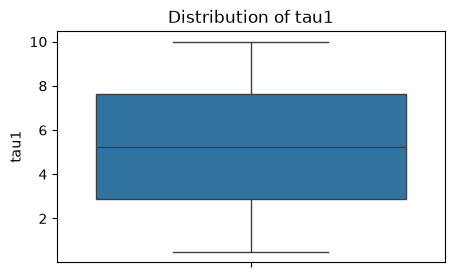

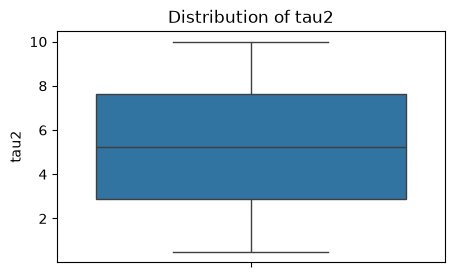

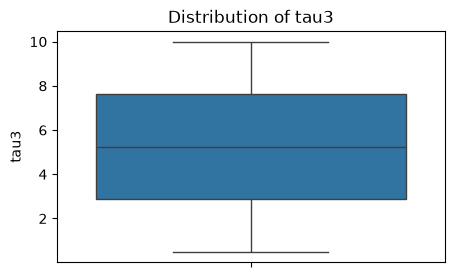

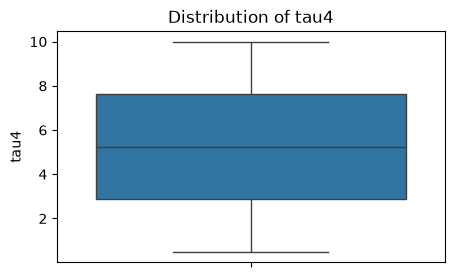

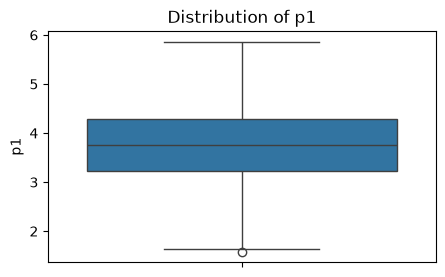

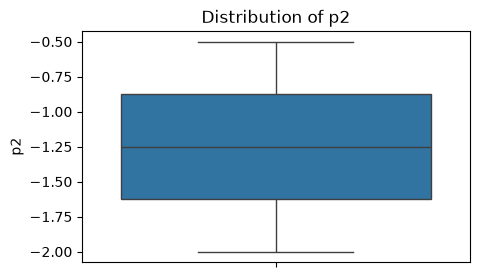

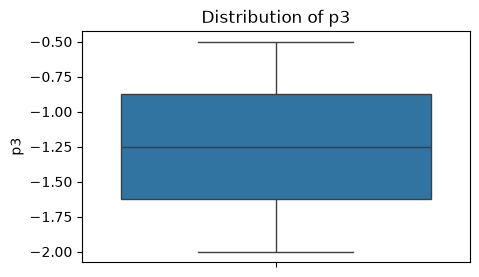

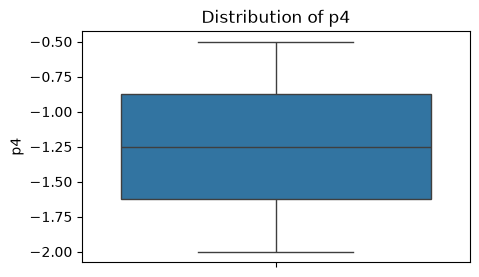

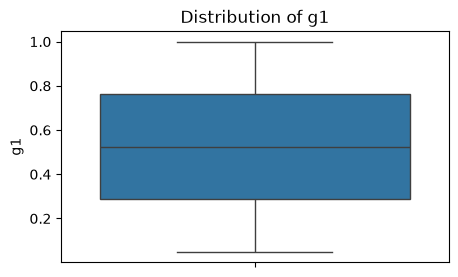

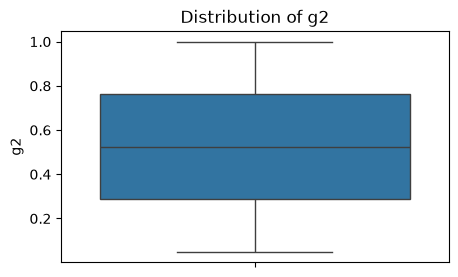

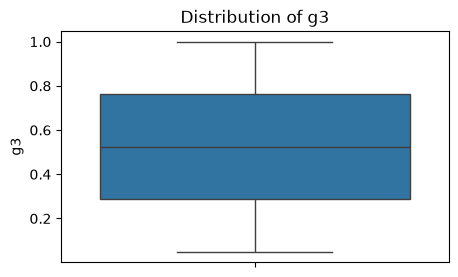

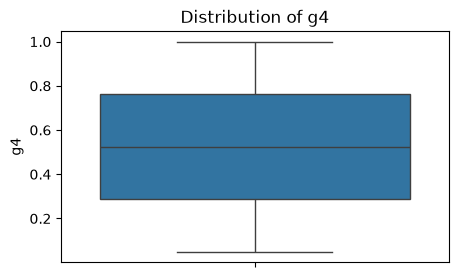

In [16]:
# Check numerical features for possible outliers
for i in num_cols:
    plot_boxplot(df, i)

In [17]:
# filling missing values
df[num_cols] = df[num_cols].fillna(df[num_cols].median())

# check again
df.isna().sum()

tau1     0
tau2     0
tau3     0
tau4     0
p1       0
p2       0
p3       0
p4       0
g1       0
g2       0
g3       0
g4       0
stabf    0
dtype: int64

In [18]:
# Count outliers in each column (1.5 * IQR rule)
for c in num_cols:
    q1 = df[c].quantile(0.25)
    q3 = df[c].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    count = ((df[c] < low) | (df[c] > high)).sum()
    print(c, '->', count, 'outliers')

tau1 -> 0 outliers
tau2 -> 0 outliers
tau3 -> 0 outliers
tau4 -> 0 outliers
p1 -> 1 outliers
p2 -> 0 outliers
p3 -> 0 outliers
p4 -> 0 outliers
g1 -> 0 outliers
g2 -> 0 outliers
g3 -> 0 outliers
g4 -> 0 outliers


In [19]:
# Cap p1 at the IQR limits
q1 = df['p1'].quantile(0.25)
q3 = df['p1'].quantile(0.75)
iqr = q3 - q1
df['p1'] = df['p1'].clip(lower=q1 - 1.5 * iqr, upper=q3 + 1.5 * iqr)

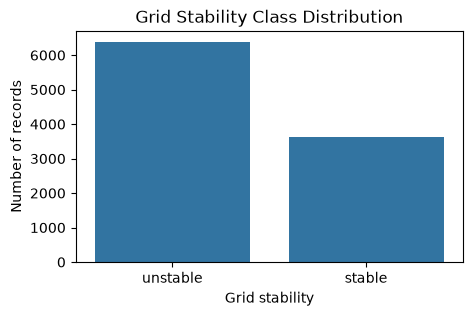

In [20]:
# Target class distribution

# Countplot 

plt.figure(figsize=(5, 3))
sns.countplot(x=df['stabf'])
plt.title('Grid Stability Class Distribution')
plt.xlabel('Grid stability')
plt.ylabel('Number of records')
plt.show()

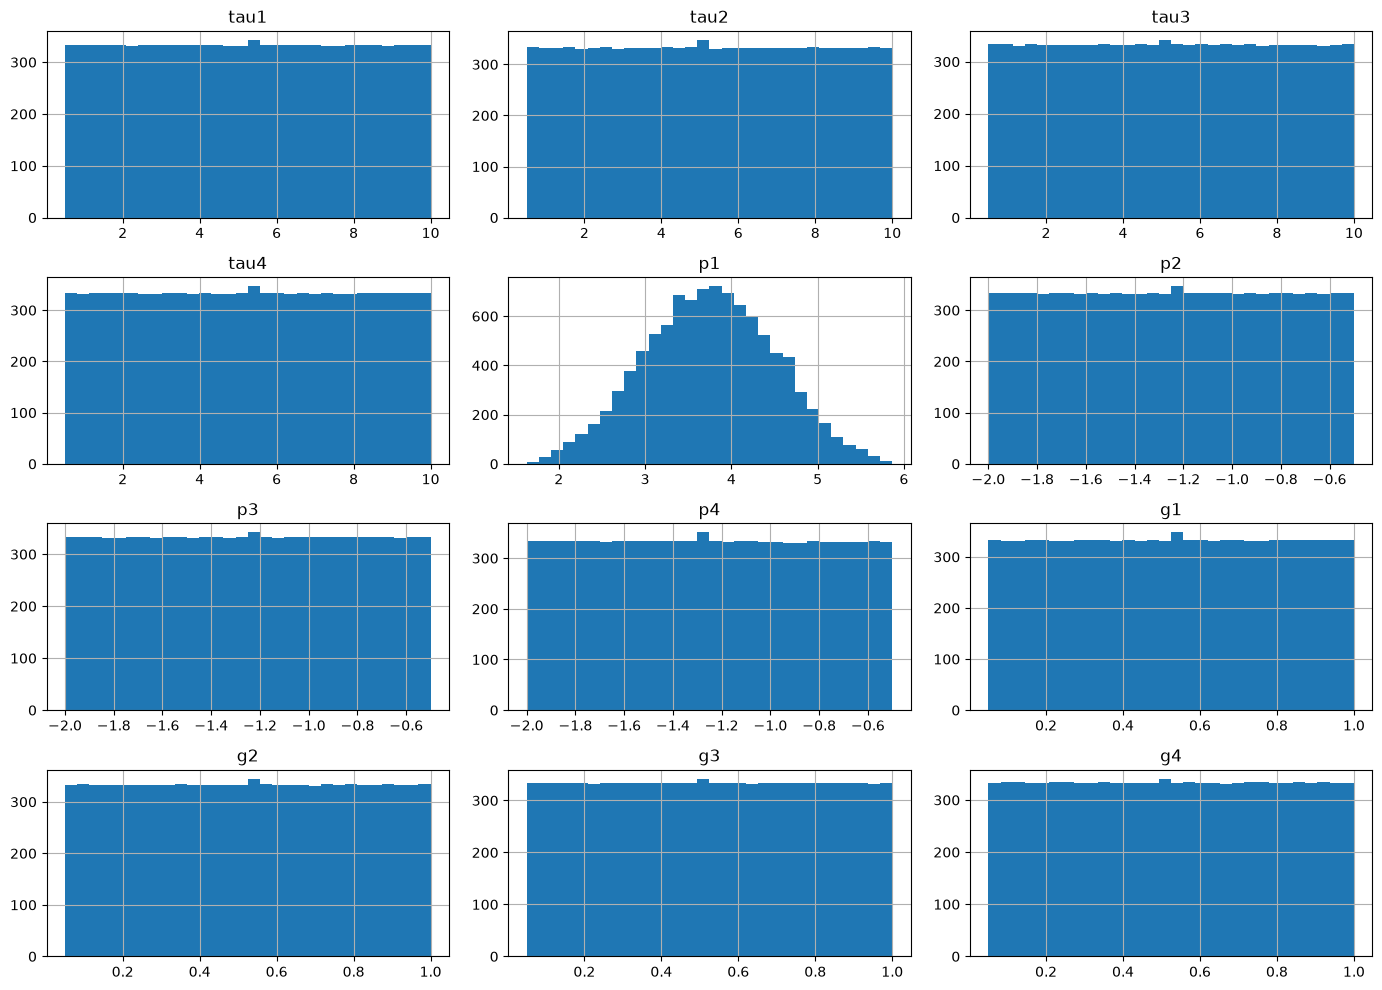

In [21]:
# Numerical Feature Distribution

# Histograms of numerical features
df[num_cols].hist(bins=30, figsize=(14, 10))
plt.tight_layout()
plt.show()

In [22]:
# Correlation between input features
df.corr(numeric_only=True)

,tau1,tau2,tau3,tau4,p1,p2,p3,p4,g1,g2,g3,g4
tau1,1.000000,0.016051,-0.006692,-0.017255,0.025890,-0.015315,-0.015658,-0.015508,0.009541,0.015626,-0.000060,0.005338
tau2,0.016051,1.000000,0.013251,-0.001460,-0.004267,0.006026,0.008256,-0.006279,-0.001864,0.015481,0.015629,-0.011621
tau3,-0.006692,0.013251,1.000000,0.003824,0.016688,-0.002919,-0.008731,-0.017258,-0.012117,0.007745,0.015413,-0.010672
tau4,-0.017255,-0.001460,0.003824,1.000000,-0.002293,0.011111,0.005851,-0.011361,-0.004177,0.007455,0.003369,-0.000740
p1,0.025890,-0.004267,0.016688,-0.002293,1.000000,-0.571999,-0.583419,-0.577578,0.001595,0.015718,0.002085,-0.016426
p2,-0.015315,0.006026,-0.002919,0.011111,-0.571999,1.000000,0.001759,-0.007516,0.015089,-0.018409,0.007636,0.020435
p3,-0.015658,0.008256,-0.008731,0.005851,-0.583419,0.001759,1.000000,0.013780,-0.003510,-0.011573,-0.006006,-0.010488
p4,-0.015508,-0.006279,-0.017258,-0.011361,-0.577578,-0.007516,0.013780,1.000000,-0.014340,0.001913,-0.004088,0.016608
g1,0.009541,-0.001864,-0.012117,-0.004177,0.001595,0.015089,-0.003510,-0.014340,1.000000,0.007244,-0.005956,0.012005
g2,0.015626,0.015481,0.007745,0.007455,0.015718,-0.018409,-0.011573,0.001913,0.007244,1.000000,-0.013435,-0.015148


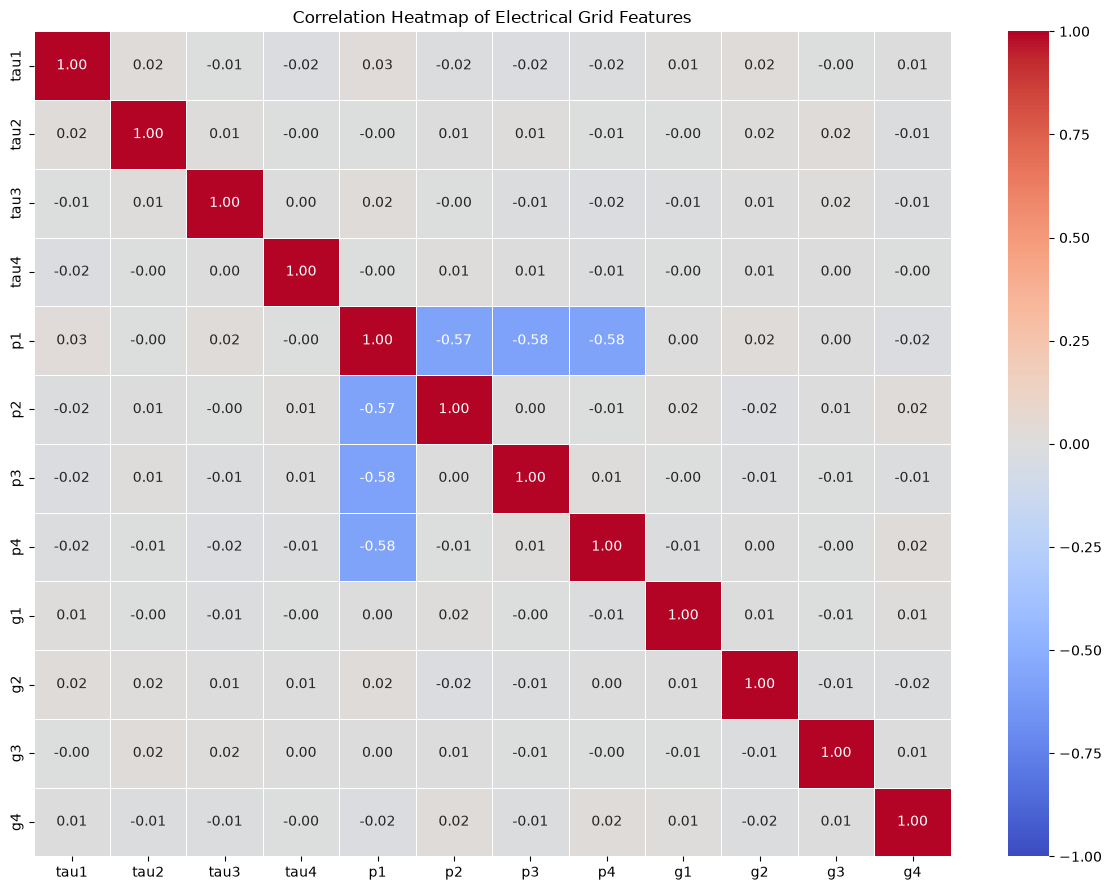

In [23]:
# Correlation heatmap
plt.figure(figsize=(12, 9))

sns.heatmap(
    df[num_cols].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Electrical Grid Features")
plt.tight_layout()
plt.show()

In [24]:
print(df[num_cols].nunique())

tau1    9991
tau2    9985
tau3    9991
tau4    9985
p1      9983
p2      9987
p3      9991
p4      9983
g1      9985
g2      9989
g3      9991
g4      9991
dtype: int64


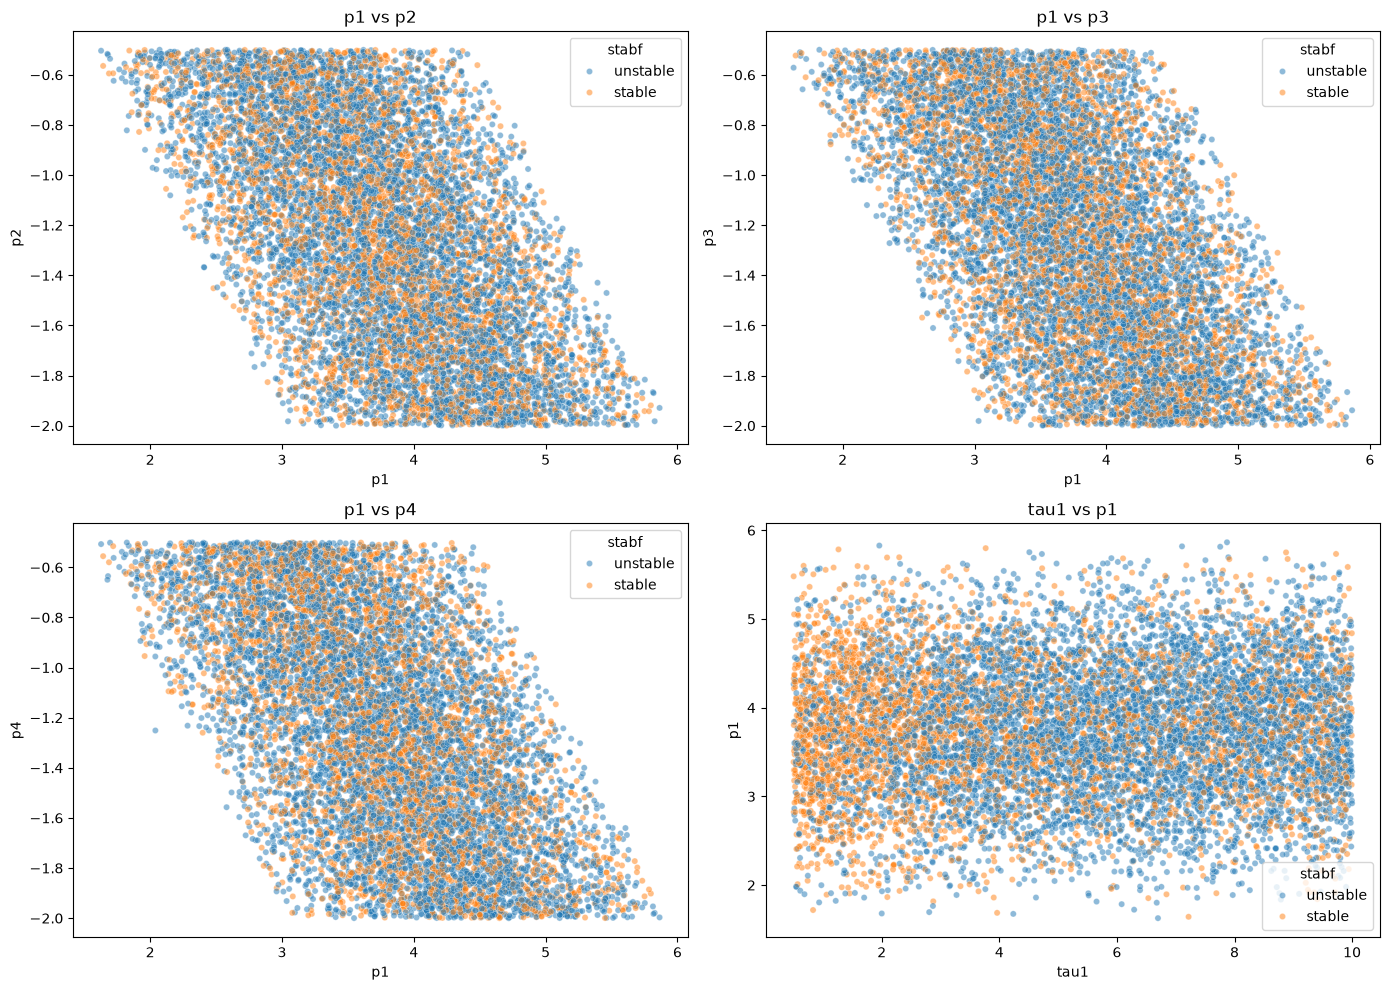

In [25]:
# Scatter plots to analyse relationships between electrical features

plt.figure(figsize=(14, 10))

features = [('p1', 'p2'),
            ('p1', 'p3'),
            ('p1', 'p4'),
            ('tau1', 'p1')]

for i, (x, y) in enumerate(features, 1):

    plt.subplot(2, 2, i)

    sns.scatterplot(
        data=df,
        x=x,
        y=y,
        hue='stabf',
        alpha=0.5,
        s=20
    )
    plt.title(f'{x} vs {y}')

plt.tight_layout()
plt.show()

In [26]:
# seperating independent features and Target variable

X = df.drop('stabf', axis=1)
y = df['stabf']

In [27]:
# Train-test split

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [28]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (8000, 12)
X_test: (2000, 12)
y_train: (8000,)
y_test: (2000,)


In [29]:
# Encoding -- label encoding on XGBoost

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

In [42]:
print(label_encoder.classes_)

['stable' 'unstable']


In [43]:
# Feature scaling
# scaling on Logistic Regression,KNN,SVM

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [44]:
print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

Training data shape: (8000, 12)
Testing data shape: (2000, 12)


In [45]:
# train and compare classification models

log_reg = LogisticRegression(max_iter=1000, random_state=42)
knn = KNeighborsClassifier()
svm = SVC()
naive_bayes = GaussianNB()
d_tree = DecisionTreeClassifier(random_state=42)
rf = RandomForestClassifier(random_state=42)
ada = AdaBoostClassifier(random_state=42)
gb = GradientBoostingClassifier(random_state=42)
xgb=XGBClassifier(random_state=42)

models = [log_reg, knn, svm, naive_bayes, d_tree, rf, ada, gb, xgb]

In [46]:

results = []

scaled_models = [log_reg, knn, svm]

for model in models:

    print(model)

    # Select appropriate training and testing data
    if model in scaled_models:
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)

    elif isinstance(model, XGBClassifier):
        model.fit(X_train, y_train_encoded)
        y_pred = model.predict(X_test)
        y_pred = label_encoder.inverse_transform(y_pred.astype(int))

    # Other algorithms use orignal data
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

    # Evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    recall = recall_score(y_test, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)

    print('Accuracy:', accuracy)
    print('Precision:', precision)
    print('Recall:', recall)
    print('F1 Score:', f1)
    print('-' * 70)

    # calculate perfomance
    results.append({
        'Model': type(model).__name__,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1
    })

results_df = pd.DataFrame(results).sort_values(by='F1 Score', ascending=False)
results_df


LogisticRegression(max_iter=1000, random_state=42)
Accuracy: 0.8205
Precision: 0.8183518147507023
Recall: 0.8205
F1 Score: 0.8183719890580876
----------------------------------------------------------------------
KNeighborsClassifier()
Accuracy: 0.8635
Precision: 0.8656581921415843
Recall: 0.8635
F1 Score: 0.8597780361156321
----------------------------------------------------------------------
SVC()
Accuracy: 0.9635
Precision: 0.9634403567447045
Recall: 0.9635
F1 Score: 0.9634386254147738
----------------------------------------------------------------------
GaussianNB()
Accuracy: 0.843
Precision: 0.8441983171029642
Recall: 0.843
F1 Score: 0.8384453500858006
----------------------------------------------------------------------
DecisionTreeClassifier(random_state=42)
Accuracy: 0.847
Precision: 0.8478199056199056
Recall: 0.847
F1 Score: 0.8473534157314992
----------------------------------------------------------------------
RandomForestClassifier(random_state=42)
Accuracy: 0.924
Preci

,Model,Accuracy,Precision,Recall,F1 Score
2,SVC,0.9635,0.963440,0.9635,0.963439
8,XGBClassifier,0.9485,0.948390,0.9485,0.948331
7,GradientBoostingClassifier,0.9335,0.933606,0.9335,0.932986
5,RandomForestClassifier,0.9240,0.923822,0.9240,0.923507
1,KNeighborsClassifier,0.8635,0.865658,0.8635,0.859778
6,AdaBoostClassifier,0.8610,0.860276,0.8610,0.858877
4,DecisionTreeClassifier,0.8470,0.847820,0.8470,0.847353
3,GaussianNB,0.8430,0.844198,0.8430,0.838445
0,LogisticRegression,0.8205,0.818352,0.8205,0.818372


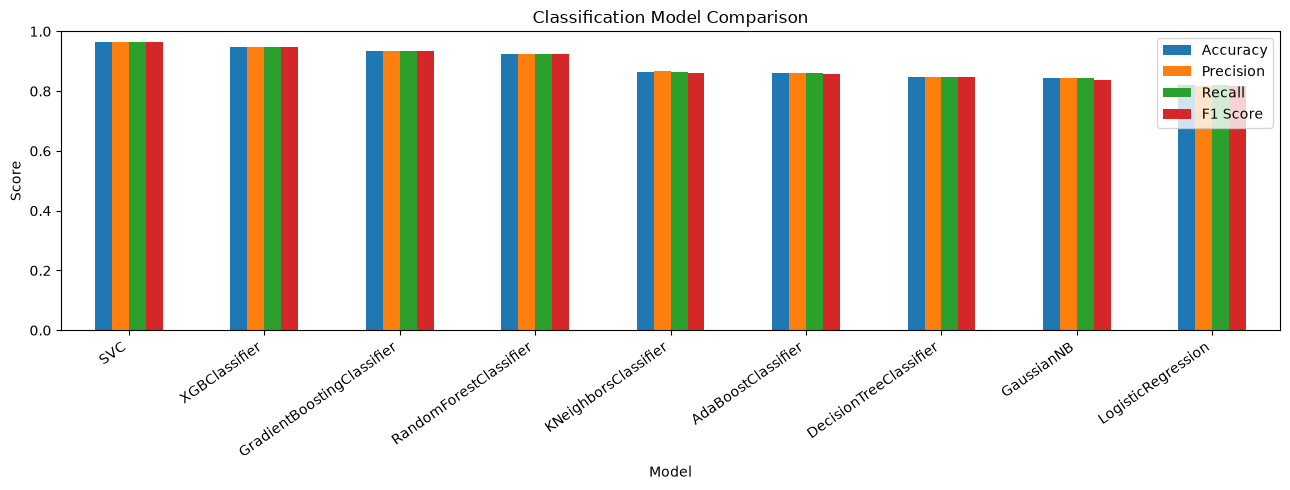

In [48]:
# Compare model scores

results_df.set_index('Model')[['Accuracy', 'Precision', 'Recall', 'F1 Score']].plot(
    kind='bar', figsize=(13, 5)
)

plt.title('Classification Model Comparison')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

In [49]:
# SVC hyperparameter tuning

svm = SVC()
params = {'C': [0.1, 1, 10, 100],'kernel': ['linear', 'rbf','poly'],'gamma': ['scale', 'auto']}
search = RandomizedSearchCV(svm,params,n_iter=6,cv=5,scoring='f1_macro',random_state=42,n_jobs=-1)
search.fit(X_train_scaled, y_train)

model= search.best_estimator_

print('Best parameters:', search.best_params_)
print('Best cross-validation F1 score:', search.best_score_)

Best parameters: {'kernel': 'rbf', 'gamma': 'auto', 'C': 10}
Best cross-validation F1 score: 0.9558962140084126


In [50]:
# Evaluate tuned SVC model

y_pred= model.predict(X_test_scaled)

print("Accuracy:",accuracy_score(y_test, y_pred))
print("Classification Report:\n",classification_report(y_test, y_pred))

Accuracy: 0.972
Classification Report:
               precision    recall  f1-score   support

      stable       0.96      0.96      0.96       724
    unstable       0.98      0.98      0.98      1276

    accuracy                           0.97      2000
   macro avg       0.97      0.97      0.97      2000
weighted avg       0.97      0.97      0.97      2000



In [51]:
# training accurcy of SVM

y_train_pred = model.predict(X_train_scaled)

print("SVM Training Accuracy:",
      accuracy_score(y_train, y_train_pred))

SVM Training Accuracy: 0.995625


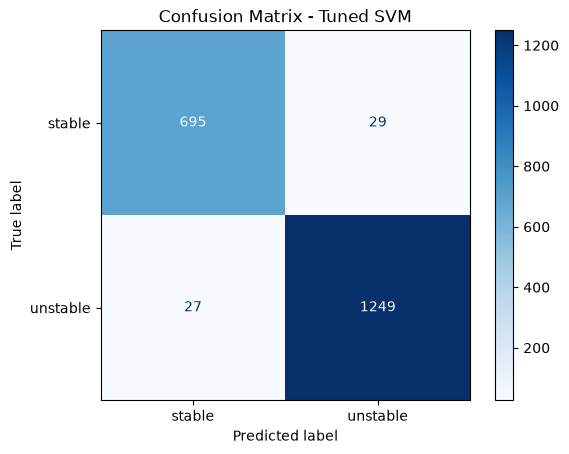

In [52]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
disp.plot(cmap='Blues')
plt.title('Confusion Matrix - Tuned SVM')
plt.show()

In [53]:
print(model.predict(scaler.transform([[2.930406,	9.487627,	2.376523,	6.187797,	3.343416,	-0.658054,	-1.449106,	-1.236256,	0.601709,	0.779642,	0.813512,	0.608385]])))
print(model.predict(scaler.transform([[3.392299,1.274827,	2.954947,	6.894759,	4.349512,	-1.663661,	-0.952437,	-1.733414,	0.502079,	0.567242,	0.285880,	0.366120]])))

['unstable']
['stable']


c:\Users\HP\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\Users\HP\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [54]:
# Save the best model and scaler
pickle.dump(model, open('svc_model.sav', 'wb'))
pickle.dump(scaler, open('svc_scaler.sav', 'wb'))

print('Model and scaler saved successfully.')

Model and scaler saved successfully.


In [55]:
# Load saved model and scaler
loaded_model = pickle.load(open('svc_model.sav', 'rb'))
loaded_scaler = pickle.load(open('svc_scaler.sav', 'rb'))

# Try predictions on five rows
sample_data = df.drop(columns=['stabf'], errors='ignore').head(5)
sample_data_scaled = loaded_scaler.transform(sample_data)

sample_predictions = loaded_model.predict(sample_data_scaled)

print('Actual classes:', y.head(5).tolist())
print('Predicted classes:', sample_predictions)

Actual classes: ['unstable', 'stable', 'unstable', 'unstable', 'unstable']
Predicted classes: ['unstable' 'stable' 'unstable' 'unstable' 'unstable']
